# 02. Credit Risk - классификация

Бинарная классификация: предсказать `loan_status` (0 - кредит возвращён, 1 - дефолт).

**Датасет:** 32 581 × 12. **Дисбаланс классов:** 78.2 / 21.8.

**Протокол (одинаковый для credit и churn):**

1. Проверка качества данных: невозможные значения, дубликаты, пропуски.
2. Правила очистки, не зависящие от данных (невозможное значение -> `NaN`).
3. Train / test split 80/20 со стратификацией. Тест откладывается до самого конца.
4. Условное заполнение пропусков **внутри `Pipeline`** (статистики считаются только на train-фолде).
5. Кросс-валидация `StratifiedKFold(5)` на train: 9 моделей с фиксированными гиперпараметрами, ROC-AUC + F1.
6. Подбор гиперпараметров `RandomizedSearchCV` на train для каждой модели.
7. Финальная оценка подобранных моделей на тесте.

In [1]:
import sys
from pathlib import Path

KAGGLE_CONFIG_PATHS = [
    Path("/kaggle/input/project-config"),
    Path("/kaggle/input/kirylloffix/project-config"),
]

for p in KAGGLE_CONFIG_PATHS:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
        break

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from config import Config


warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

config = Config()
RANDOM_STATE = config.RANDOM_STATE
np.random.seed(RANDOM_STATE)
print(config)

Config(mode='local', credit='/home/claude/proj/data/credit_risk_dataset.csv', churn='/home/claude/proj/data/WA_Fn-UseC_-Telco-Customer-Churn.csv', demand='/home/claude/proj/data/train.csv', random_state=42)


In [2]:
DATASET = 'credit'
PLOT_PATH = config.credit_plot

df_credit = pd.read_csv(config.path_credit)
print("credit:", df_credit.shape)
df_credit.head()

credit: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## Проверка качества данных

Прежде чем что-то чистить, смотрим **что именно** не так:

1. **Невозможные значения.** Возраст > 100 лет, стаж больше, чем `возраст − 14` (работать раньше 14 нельзя).
2. **Полные дубликаты строк.** Если одна и та же строка попадёт и в train, и в test - это утечка.
3. **Пропуски и их связь с таргетом.** Если у строк с пропуском доля дефолтов другая - пропуск сам по себе информативен,
   и удалять такие строки нельзя.
4. **От чего зависит пропущенный признак.** Заполнять «медианой внутри группы» имеет смысл, только если
   медианы в группах действительно различаются.

In [3]:
c = df_credit

print("1. Невозможные значения")
print(f"   person_age > 100:                     {(c['person_age'] > 100).sum()} строк -> {sorted(c.loc[c['person_age'] > 100, 'person_age'].tolist())}")
print(f"   person_emp_length > person_age - 14:  {(c['person_emp_length'] > c['person_age'] - 14).sum()} строк -> "
      f"{c.loc[c['person_emp_length'] > c['person_age'] - 14, ['person_age', 'person_emp_length']].values.tolist()}")

print(f"\n2. Полных дубликатов строк: {c.duplicated().sum()}")

print("\n3. Пропуски и доля дефолтов")
print(f"   вся выборка:                      {c['loan_status'].mean():.3f}")
for col in ['person_emp_length', 'loan_int_rate']:
    m = c[col].isna()
    print(f"   {col:18} NaN: {m.sum():5d} строк, доля дефолтов среди них: {c.loc[m, 'loan_status'].mean():.3f}")

print("\n4. Медиана person_emp_length по группам")
age_group = pd.cut(c['person_age'], bins=[0, 25, 35, 45, 60, 200])
print("   по возрасту:", c.groupby(age_group, observed=True)['person_emp_length'].median().to_dict())
print("   по типу жилья:", c.groupby('person_home_ownership')['person_emp_length'].median().to_dict())
inc_q = pd.qcut(c['person_income'], 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
print("   по квинтилю дохода:", c.groupby(inc_q, observed=True)['person_emp_length'].median().to_dict())

print("\n   Медиана loan_int_rate по loan_grade:", c.groupby('loan_grade')['loan_int_rate'].median().to_dict())
print(f"\n   Корреляция person_age и cb_person_cred_hist_length: {c['person_age'].corr(c['cb_person_cred_hist_length']):.3f}")

1. Невозможные значения
   person_age > 100:                     5 строк -> [123, 123, 144, 144, 144]
   person_emp_length > person_age - 14:  2 строк -> [[22.0, 123.0], [21.0, 123.0]]

2. Полных дубликатов строк: 165

3. Пропуски и доля дефолтов
   вся выборка:                      0.218
   person_emp_length  NaN:   895 строк, доля дефолтов среди них: 0.315
   loan_int_rate      NaN:  3116 строк, доля дефолтов среди них: 0.207

4. Медиана person_emp_length по группам
   по возрасту: {Interval(0, 25, closed='right'): 4.0, Interval(25, 35, closed='right'): 4.0, Interval(35, 45, closed='right'): 4.0, Interval(45, 60, closed='right'): 4.0, Interval(60, 200, closed='right'): 3.0}
   по типу жилья: {'MORTGAGE': 5.0, 'OTHER': 3.0, 'OWN': 4.0, 'RENT': 3.0}
   по квинтилю дохода: {'Q1': 3.0, 'Q2': 4.0, 'Q3': 4.0, 'Q4': 5.0, 'Q5': 5.0}

   Медиана loan_int_rate по loan_grade: {'A': 7.49, 'B': 10.99, 'C': 13.48, 'D': 15.31, 'E': 16.82, 'F': 18.535, 'G': 20.16}

   Корреляция person_age и cb_pers

### Что показала проверка

- **Ошибка в прошлой версии ноутбука.** Фильтр `credit[credit['person_emp_length'] <= 60]` удалял **все 895 строк с пропуском**
  стажа, потому что `NaN <= 60` даёт `False`. Поэтому получалось 31 679 строк, а заполнение пропусков стажа ни разу не срабатывало.
  Это смещает выборку: у этих клиентов доля дефолтов заметно выше средней.
- **Медиана стажа одинакова (4 года) во всех возрастных группах** - группировка по возрасту ничего не даёт,
  это было бы то же самое, что глобальная медиана. А вот **по типу жилья и доходу** медианы реально различаются (3-5 лет).
- **Ставка сильно зависит от грейда** (A ≈ 7.5%, G ≈ 20%) - условное заполнение по `loan_grade` оправдано.
- **Возраст сильно коррелирует с длиной кредитной истории** (≈ 0.86) - по ней можно восстановить невозможный возраст.

## Правила очистки (до разбиения)

Эти правила **не обучаются на данных** (это фиксированные логические условия), поэтому их можно применить до разбиения - утечки нет.

- Полные дубликаты удаляем (иначе одна строка может оказаться и в train, и в test).
- `person_age > 100` -> `NaN` (ошибка ввода, восстановим ниже).
- `person_emp_length > person_age − 14` -> `NaN` (стаж 123 года у 21-летнего).

Строки **не удаляем**: невозможное значение - это такой же пропуск, его надо заполнить разумно.

In [4]:
credit = df_credit.copy()

n_before = len(credit)
credit = credit.drop_duplicates().reset_index(drop=True)
print(f"удалено дубликатов: {n_before - len(credit)}")

bad_emp = credit['person_emp_length'] > credit['person_age'] - 14
bad_age = credit['person_age'] > 100
credit.loc[bad_emp, 'person_emp_length'] = np.nan
credit.loc[bad_age, 'person_age'] = np.nan
print(f"невозможный стаж -> NaN:   {bad_emp.sum()}")
print(f"невозможный возраст -> NaN: {bad_age.sum()}")

print(f"\nshape: {credit.shape}")
print("пропуски:")
print(credit.isna().sum()[lambda s: s > 0])

удалено дубликатов: 165
невозможный стаж -> NaN:   2
невозможный возраст -> NaN: 5

shape: (32416, 12)
пропуски:
person_age              5
person_emp_length     889
loan_int_rate        3095
dtype: int64


## Условное заполнение пропусков внутри Pipeline

**Почему внутри `Pipeline`.** Медианы групп - это статистики, «выученные» по данным. Если посчитать их по всей таблице до разбиения,
в них попадёт информация из теста (утечка). Поэтому пишем маленький sklearn-трансформер:

- `fit` - считает медианы групп **только по train** (в CV - по train-фолду);
- `transform` - подставляет их в train, валидацию и тест.

**Правила заполнения (выбраны по проверке выше):**

| Колонка | Чем заполняем | Почему |
|---|---|---|
| `person_age` | медиана внутри `cb_person_cred_hist_length` | корреляция ≈ 0.86 |
| `person_emp_length` | медиана внутри `person_home_ownership` × квинтиль `person_income` | по возрасту медианы одинаковые, по жилью и доходу - различаются |
| `loan_int_rate` | медиана внутри `loan_grade` | ставка определяется грейдом |

Если комбинация группы не встречалась в train - берём глобальную медиану (страховка).

**Флаги пропуска** `*_was_missing` (0/1): у клиентов без указанного стажа доля дефолтов выше,
поэтому сам факт пропуска - полезный признак (informative missingness).

In [5]:
from sklearn.base import BaseEstimator, TransformerMixin


class ConditionalMedianImputer(BaseEstimator, TransformerMixin):
    """
    Заполняет пропуски медианой внутри группы похожих объектов.

    rules      - {колонка: [колонки-группы]}; группа может быть '<col>_bin' для колонки из bins
    bins       - {колонка: число квантильных корзин}; границы считаются в fit
    indicators - колонки, для которых добавляется флаг <col>_was_missing
    """

    def __init__(self, rules, bins=None, indicators=None):
        self.rules = rules
        self.bins = bins
        self.indicators = indicators

    def _add_bins(self, X):
        X = X.copy()
        for col, edges in self.bin_edges_.items():
            X[f'{col}_bin'] = pd.cut(X[col], edges, labels=False, include_lowest=True)
        return X

    def fit(self, X, y=None):
        self.bin_edges_ = {}
        for col, q in (self.bins or {}).items():
            edges = np.unique(np.quantile(X[col].dropna(), np.linspace(0, 1, q + 1)))
            edges[0], edges[-1] = -np.inf, np.inf
            self.bin_edges_[col] = edges

        Xb = self._add_bins(X)
        self.group_medians_, self.global_medians_ = {}, {}
        for target, groups in self.rules.items():
            self.group_medians_[target] = Xb.groupby(groups)[target].median().rename('_median').reset_index()
            self.global_medians_[target] = Xb[target].median()
        return self

    def transform(self, X):
        Xb = self._add_bins(X)
        out = X.copy()
        for col in (self.indicators or []):
            out[f'{col}_was_missing'] = X[col].isna().astype(int)
        for target, groups in self.rules.items():
            mask = out[target].isna()
            if mask.any():
                fill = (Xb.loc[mask, groups]
                        .merge(self.group_medians_[target], on=groups, how='left')['_median']
                        .to_numpy(dtype=float))
                fill = np.where(np.isnan(fill), self.global_medians_[target], fill)
                out.loc[mask, target] = fill
        return out


IMPUTE_RULES = {
    'person_age':        ['cb_person_cred_hist_length'],
    'person_emp_length': ['person_home_ownership', 'person_income_bin'],
    'loan_int_rate':     ['loan_grade'],
}


def make_imputer():
    return ConditionalMedianImputer(
        rules=IMPUTE_RULES,
        bins={'person_income': 5},
        indicators=['person_emp_length', 'loan_int_rate'],
    )

## Train / test split

`stratify=y` сохраняет пропорцию классов в обоих наборах. `random_state=42` фиксирует разбиение.

Тест (20%) **откладываем** и не трогаем до финальной оценки.

In [6]:
from sklearn.model_selection import train_test_split


X = credit.drop(columns=['loan_status'])
y = credit['loan_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"train: {X_train.shape}, test: {X_test.shape}")
print(f"доля класса 1 в train: {y_train.mean():.4f}")
print(f"доля класса 1 в test:  {y_test.mean():.4f}")

train: (25932, 11), test: (6484, 11)
доля класса 1 в train: 0.2187
доля класса 1 в test:  0.2187


### Проверка заполнения

Обучаем импьютер на train и смотрим, что он подставил. Для сравнения - что дала бы глобальная медиана.

In [7]:
imp = make_imputer().fit(X_train)
X_train_filled = imp.transform(X_train)

for col in IMPUTE_RULES:
    m = X_train[col].isna()
    if m.any():
        filled = X_train_filled.loc[m, col]
        print(f"{col:18} заполнено {m.sum():4d}: уникальных подстановок {filled.nunique():2d}, "
              f"диапазон [{filled.min():.2f}; {filled.max():.2f}], глобальная медиана {X_train[col].median():.2f}")

print(f"\nпропусков после заполнения: {X_train_filled.isna().sum().sum()}")
print("новые колонки:", [c for c in X_train_filled.columns if c.endswith('_was_missing')])
X_train_filled.loc[X_train['loan_int_rate'].isna(), ['loan_grade', 'loan_int_rate', 'loan_int_rate_was_missing']].head()

person_age         заполнено    5: уникальных подстановок  3, диапазон [23.00; 52.00], глобальная медиана 26.00
person_emp_length  заполнено  729: уникальных подстановок  6, диапазон [2.00; 7.00], глобальная медиана 4.00
loan_int_rate      заполнено 2488: уникальных подстановок  7, диапазон [7.49; 20.11], глобальная медиана 10.99

пропусков после заполнения: 0
новые колонки: ['person_emp_length_was_missing', 'loan_int_rate_was_missing']


,loan_grade,loan_int_rate,loan_int_rate_was_missing
2809,A,7.49,1
26708,B,10.99,1
10841,B,10.99,1
22784,A,7.49,1
15619,A,7.49,1


## Препроцессор и пайплайн

**`Pipeline`** = условное заполнение -> кодирование/масштабирование -> модель. Внутри CV всё обучается **только на train-фолде**.

**`ColumnTransformer`:**
- `StandardScaler` к числовым (нужен LogReg, SVM, kNN; деревьям не мешает);
- `OneHotEncoder` к категориальным (кардинальность ≤ 7, раздувания нет).

Колонки выбираются по типу (`make_column_selector`), потому что импьютер добавляет новые числовые колонки-флаги.

**Baseline - LogReg.** Если сложная модель не бьёт логистическую регрессию - что-то не так.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression


def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), make_column_selector(dtype_include='number')),
        ('cat', OneHotEncoder(handle_unknown='ignore'), make_column_selector(dtype_exclude='number')),
    ])


def make_pipeline_for(model):
    return Pipeline([
        ('impute', make_imputer()),
        ('prep', make_preprocessor()),
        ('model', model),
    ])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipe_logreg = make_pipeline_for(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
scores = cross_val_score(pipe_logreg, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)

print(f"Baseline LogReg, ROC-AUC по фолдам: {scores.round(4)}")
print(f"Среднее: {scores.mean():.4f} ± {scores.std():.4f}")

Baseline LogReg, ROC-AUC по фолдам: [0.8677 0.8607 0.8733 0.8742 0.8767]
Среднее: 0.8705 ± 0.0057


## Кросс-валидация 9 моделей на train

Прогоняем 9 моделей **на одном и том же** пайплайне и одних и тех же фолдах:

- **Линейные:** LogReg
- **Деревья:** DecisionTree
- **Бэггинг:** RandomForest
- **Бустинг:** XGBoost, LightGBM, CatBoost
- **Метрические:** kNN
- **Разделяющая полоса (margin):** SVM (rbf)
- **Вероятностные:** NaiveBayes

Здесь гиперпараметры **фиксированные** (одинаковые «разумные значения по умолчанию» для всех датасетов).
Это первая стадия протокола: честное сравнение семейств без подгонки.

Что важно в коде:

- CV идёт **только по `X_train`**: тест не участвует ни в обучении, ни в выборе модели;
- `cross_validate` считает сразу две метрики - **ROC-AUC** и **F1** (порог 0.5);
- `return_train_score=True` - ROC-AUC на обучающих фолдах. Разница train - val показывает **переобучение**;
- `CatBoost(allow_writing_files=False)` - иначе параллельные процессы конфликтуют из-за папки `catboost_info`
  и часть фолдов падает (так было в прошлой версии 02_credit: CatBoost = `NaN`);
- у `SVC` не включаем `probability=True`: для ROC-AUC достаточно `decision_function`
  (ранжирование то же самое), а обучение в ~5 раз быстрее;
- у самих моделей `n_jobs=1` (`thread_count=1` у CatBoost): параллелим фолды (`n_jobs=-1` в `cross_validate`), а не потоки внутри модели. Иначе на 2 ядрах 2 процесса × все ядра конкурируют, и бустинги замедляются в разы. На результат это не влияет;
- метрики **по каждому фолду** сохраняются в CSV - на них потом строится тест Фридмана в `05_statistics`.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB


models = {
    'LogReg':       LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'DecisionTree': DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    'RandomForest': RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=RANDOM_STATE),
    'XGBoost':      XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                  eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=1),
    'LightGBM':     LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                   random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
    'CatBoost':     CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1,
                                       random_state=RANDOM_STATE, verbose=0,
                                       allow_writing_files=False, thread_count=1),
    'kNN':          KNeighborsClassifier(n_neighbors=15, n_jobs=1),
    'SVM':          SVC(kernel='rbf', C=1.0, random_state=RANDOM_STATE),
    'NaiveBayes':   GaussianNB(),
}

In [10]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate


fold_rows = []
results = {}

for name, model in models.items():
    pipe = make_pipeline_for(clone(model))
    cvres = cross_validate(
        pipe, X_train, y_train,
        cv=cv,
        scoring={'roc_auc': 'roc_auc', 'f1': 'f1'},
        return_train_score=True,
        n_jobs=-1,
        error_score='raise',
    )
    for i in range(cv.get_n_splits()):
        fold_rows.append({
            'dataset': DATASET, 'model': name, 'fold': i,
            'roc_auc': cvres['test_roc_auc'][i],
            'f1': cvres['test_f1'][i],
            'train_roc_auc': cvres['train_roc_auc'][i],
        })
    results[name] = {
        'roc_auc_mean':  cvres['test_roc_auc'].mean(),
        'roc_auc_std':   cvres['test_roc_auc'].std(),
        'f1_mean':       cvres['test_f1'].mean(),
        'f1_std':        cvres['test_f1'].std(),
        'train_roc_auc': cvres['train_roc_auc'].mean(),
    }
    print(f"{name:15} ROC-AUC: {cvres['test_roc_auc'].mean():.4f} ± {cvres['test_roc_auc'].std():.4f}   "
          f"F1: {cvres['test_f1'].mean():.4f} ± {cvres['test_f1'].std():.4f}   "
          f"train ROC-AUC: {cvres['train_roc_auc'].mean():.4f}")

LogReg          ROC-AUC: 0.8705 ± 0.0057   F1: 0.6431 ± 0.0120   train ROC-AUC: 0.8715


DecisionTree    ROC-AUC: 0.9085 ± 0.0027   F1: 0.8169 ± 0.0041   train ROC-AUC: 0.9321


RandomForest    ROC-AUC: 0.9301 ± 0.0022   F1: 0.8240 ± 0.0045   train ROC-AUC: 1.0000


XGBoost         ROC-AUC: 0.9478 ± 0.0029   F1: 0.8350 ± 0.0026   train ROC-AUC: 0.9840


LightGBM        ROC-AUC: 0.9486 ± 0.0013   F1: 0.8347 ± 0.0035   train ROC-AUC: 0.9860


CatBoost        ROC-AUC: 0.9406 ± 0.0018   F1: 0.8333 ± 0.0024   train ROC-AUC: 0.9627


kNN             ROC-AUC: 0.8800 ± 0.0059   F1: 0.6883 ± 0.0030   train ROC-AUC: 0.9279


SVM             ROC-AUC: 0.8956 ± 0.0020   F1: 0.7558 ± 0.0079   train ROC-AUC: 0.9114


NaiveBayes      ROC-AUC: 0.8307 ± 0.0037   F1: 0.5184 ± 0.0667   train ROC-AUC: 0.8311


## Таблица результатов CV

Сортировка по среднему ROC-AUC, убывание.

`overfit_gap` = ROC-AUC на train-фолдах − ROC-AUC на валидации. Чем больше, тем сильнее модель «зазубрила» обучающие данные.

In [11]:
results_df = pd.DataFrame(results).T.sort_values('roc_auc_mean', ascending=False)
results_df['overfit_gap'] = results_df['train_roc_auc'] - results_df['roc_auc_mean']
print(results_df.round(4))

folds_df = pd.DataFrame(fold_rows)
folds_df.to_csv(config.cv_folds(DATASET), index=False)
print(f"\nМетрики по фолдам сохранены: {config.cv_folds(DATASET)}")
print("Моделей:", folds_df['model'].nunique(), "| фолдов:", folds_df['fold'].nunique())

              roc_auc_mean  roc_auc_std  f1_mean  f1_std  train_roc_auc  \
LightGBM            0.9486       0.0013   0.8347  0.0035         0.9860   
XGBoost             0.9478       0.0029   0.8350  0.0026         0.9840   
CatBoost            0.9406       0.0018   0.8333  0.0024         0.9627   
RandomForest        0.9301       0.0022   0.8240  0.0045         1.0000   
DecisionTree        0.9085       0.0027   0.8169  0.0041         0.9321   
SVM                 0.8956       0.0020   0.7558  0.0079         0.9114   
kNN                 0.8800       0.0059   0.6883  0.0030         0.9279   
LogReg              0.8705       0.0057   0.6431  0.0120         0.8715   
NaiveBayes          0.8307       0.0037   0.5184  0.0667         0.8311   

              overfit_gap  
LightGBM           0.0374  
XGBoost            0.0362  
CatBoost           0.0221  
RandomForest       0.0699  
DecisionTree       0.0235  
SVM                0.0158  
kNN                0.0478  
LogReg             0.0010

## Bar plot

Топ-3 - зелёным, остальные - синим. Усы - стандартное отклонение по 5 фолдам.

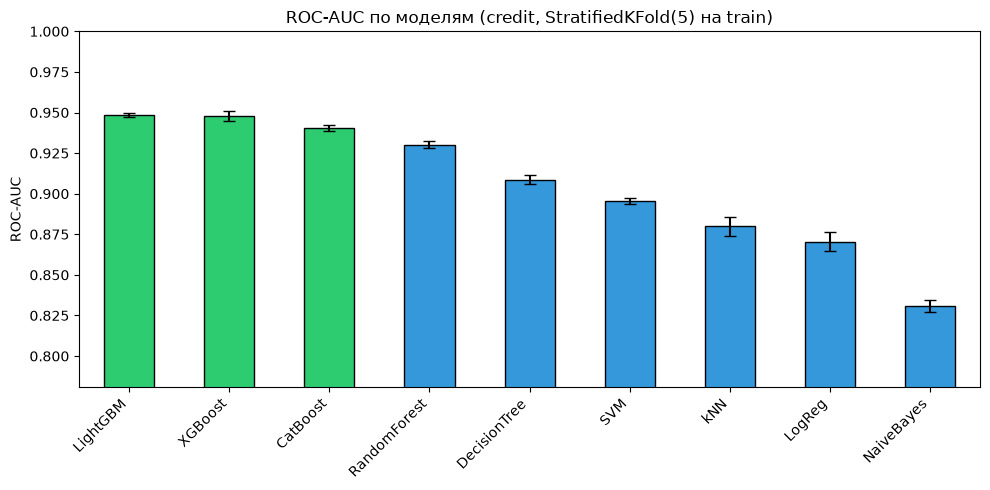

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#2ecc71' if i < 3 else '#3498db' for i in range(len(results_df))]

results_df['roc_auc_mean'].plot(
    kind='bar', yerr=results_df['roc_auc_std'], ax=ax,
    color=colors, capsize=4, edgecolor='black'
)
ax.set_ylim(results_df['roc_auc_mean'].min() - 0.05, 1.0)
ax.set_title(f'ROC-AUC по моделям ({DATASET}, StratifiedKFold(5) на train)')
ax.set_ylabel('ROC-AUC')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(PLOT_PATH, dpi=150)
plt.show()

## Подбор гиперпараметров (RandomizedSearchCV)

Вторая стадия протокола. Для **каждой** модели:

1. `RandomizedSearchCV` перебирает `n_iter` случайных комбинаций гиперпараметров;
2. каждая комбинация оценивается внутренней кросс-валидацией `StratifiedKFold(3)` **только на train**;
3. лучшая комбинация переобучается на всём train (`refit=True`);
4. итоговая модель **один раз** оценивается на отложенном тесте.

`n_iter = 20` для большинства моделей, 15 - для моделей с 1 гиперпараметром, 8 - для SVM (она самая медленная).
Это компромисс между качеством подбора и временем на 2 ядрах.

**Почему тест честный:** тест не участвовал ни в выборе гиперпараметров, ни в выборе модели.

`cv_roc_auc_tuned` - лучший результат внутри поиска. Он **оптимистичен** (мы выбрали максимум из многих попыток),
поэтому сравниваем модели по `test_roc_auc`.

In [13]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform


param_spaces = {
    'LogReg': {
        'model__C': loguniform(1e-3, 1e2),
    },
    'DecisionTree': {
        'model__max_depth': [3, 4, 5, 6, 8, 10, 12, 15, None],
        'model__min_samples_leaf': randint(1, 100),
    },
    'RandomForest': {
        'model__n_estimators': [200, 300, 400],
        'model__max_depth': [None, 10, 15, 20, 30],
        'model__min_samples_leaf': [1, 2, 4, 8],
        'model__max_features': ['sqrt', 0.3, 0.5],
    },
    'XGBoost': {
        'model__n_estimators': randint(200, 700),
        'model__max_depth': randint(3, 10),
        'model__learning_rate': loguniform(0.01, 0.3),
        'model__subsample': uniform(0.6, 0.4),
        'model__colsample_bytree': uniform(0.6, 0.4),
        'model__min_child_weight': randint(1, 10),
    },
    'LightGBM': {
        'model__n_estimators': randint(200, 700),
        'model__num_leaves': randint(15, 128),
        'model__max_depth': [-1, 6, 8, 10],
        'model__learning_rate': loguniform(0.01, 0.3),
        'model__subsample': uniform(0.6, 0.4),
        'model__subsample_freq': [1],
        'model__colsample_bytree': uniform(0.6, 0.4),
        'model__min_child_samples': randint(5, 100),
    },
    'CatBoost': {
        'model__iterations': randint(200, 600),
        'model__depth': randint(4, 9),
        'model__learning_rate': loguniform(0.01, 0.3),
        'model__l2_leaf_reg': loguniform(1, 10),
    },
    'kNN': {
        'model__n_neighbors': randint(5, 150),
        'model__weights': ['uniform', 'distance'],
    },
    'SVM': {
        'model__C': loguniform(0.1, 100),
        'model__gamma': ['scale', 0.01, 0.03, 0.1, 0.3],
    },
    'NaiveBayes': {
        'model__var_smoothing': loguniform(1e-12, 1e-2),
    },
}

N_ITER = {name: 20 for name in models}
N_ITER.update({'LogReg': 15, 'NaiveBayes': 15, 'SVM': 8})

inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

In [14]:
import time
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score


def ranking_scores(estimator, X):
    """Оценки для ROC-AUC: вероятность класса 1 или decision_function (у SVC без probability)."""
    if hasattr(estimator, 'predict_proba'):
        return estimator.predict_proba(X)[:, 1]
    return estimator.decision_function(X)


test_rows = []

for name, model in models.items():
    t0 = time.time()
    search = RandomizedSearchCV(
        make_pipeline_for(clone(model)),
        param_distributions=param_spaces[name],
        n_iter=N_ITER[name],
        cv=inner_cv,
        scoring='roc_auc',
        n_jobs=-1,
        random_state=RANDOM_STATE,
        refit=True,
    )
    search.fit(X_train, y_train)
    best = search.best_estimator_

    y_score = ranking_scores(best, X_test)
    y_pred = best.predict(X_test)

    test_rows.append({
        'dataset': DATASET,
        'model': name,
        'cv_roc_auc_default': results[name]['roc_auc_mean'],
        'cv_roc_auc_tuned': search.best_score_,
        'test_roc_auc': roc_auc_score(y_test, y_score),
        'test_f1': f1_score(y_test, y_pred),
        'test_precision': precision_score(y_test, y_pred),
        'test_recall': recall_score(y_test, y_pred),
        'best_params': {k.replace('model__', ''): (round(float(v), 5) if isinstance(v, (float, np.floating)) else v)
                        for k, v in search.best_params_.items()},
    })
    print(f"{name:15} CV(default) {results[name]['roc_auc_mean']:.4f} -> CV(tuned) {search.best_score_:.4f} | "
          f"TEST ROC-AUC {test_rows[-1]['test_roc_auc']:.4f}  F1 {test_rows[-1]['test_f1']:.4f}  "
          f"({time.time() - t0:.0f} c)")

LogReg          CV(default) 0.8705 -> CV(tuned) 0.8706 | TEST ROC-AUC 0.8687  F1 0.6539  (4 c)


DecisionTree    CV(default) 0.9085 -> CV(tuned) 0.9123 | TEST ROC-AUC 0.9073  F1 0.7585  (5 c)


RandomForest    CV(default) 0.9301 -> CV(tuned) 0.9332 | TEST ROC-AUC 0.9319  F1 0.8345  (179 c)


XGBoost         CV(default) 0.9478 -> CV(tuned) 0.9467 | TEST ROC-AUC 0.9488  F1 0.8389  (37 c)


LightGBM        CV(default) 0.9486 -> CV(tuned) 0.9469 | TEST ROC-AUC 0.9486  F1 0.8362  (55 c)


CatBoost        CV(default) 0.9406 -> CV(tuned) 0.9427 | TEST ROC-AUC 0.9425  F1 0.8399  (85 c)


kNN             CV(default) 0.8800 -> CV(tuned) 0.8874 | TEST ROC-AUC 0.8869  F1 0.6778  (36 c)


SVM             CV(default) 0.8956 -> CV(tuned) 0.8977 | TEST ROC-AUC 0.8993  F1 0.7643  (147 c)


NaiveBayes      CV(default) 0.8307 -> CV(tuned) 0.8322 | TEST ROC-AUC 0.8254  F1 0.5757  (2 c)


## Итог на отложенном тесте

`test_f1`, `test_precision`, `test_recall` - при пороге 0.5. Порог не подбирался.

In [15]:
test_df = pd.DataFrame(test_rows).set_index('model').sort_values('test_roc_auc', ascending=False)
test_df.to_csv(config.test_results(DATASET))

pd.set_option('display.width', 200)
print(test_df.drop(columns=['dataset', 'best_params']).round(4))
print()
for name, row in test_df.iterrows():
    print(f"{name:15} {row['best_params']}")
print(f"\nСохранено: {config.test_results(DATASET)}")

              cv_roc_auc_default  cv_roc_auc_tuned  test_roc_auc  test_f1  test_precision  test_recall
model                                                                                                 
XGBoost                   0.9478            0.9467        0.9488   0.8389          0.9712       0.7384
LightGBM                  0.9486            0.9469        0.9486   0.8362          0.9738       0.7327
CatBoost                  0.9406            0.9427        0.9425   0.8399          0.9811       0.7341
RandomForest              0.9301            0.9332        0.9319   0.8345          0.9791       0.7271
DecisionTree              0.9085            0.9123        0.9073   0.7585          0.9060       0.6523
SVM                       0.8956            0.8977        0.8993   0.7643          0.9240       0.6516
kNN                       0.8800            0.8874        0.8869   0.6778          0.8957       0.5451
LogReg                    0.8705            0.8706        0.8687   0.6539

## Выводы

**Данные.** Удалено 165 дубликатов, 7 невозможных значений превращены в пропуски, строки с пропущенным стажем
(889 после удаления дубликатов) **возвращены** в выборку - раньше их молча удалял фильтр `<= 60`. Итог: 32 416 строк, train 25 932 / test 6 484.

1. **Иерархия семейств чёткая и одинаковая на CV и на тесте:**
   бустинг (XGBoost 0.9488, LightGBM 0.9486, CatBoost 0.9425 на тесте) > RandomForest (0.9319) > DecisionTree (0.9073)
   > SVM (0.8993) > kNN (0.8869) > LogReg (0.8687) > NaiveBayes (0.8254).
   Порядок моделей совпал во всех 5 фолдах (меняются местами только XGBoost и LightGBM).
2. **XGBoost и LightGBM неразличимы:** разница 0.0002 на тесте при стандартной ошибке ROC-AUC на тесте ≈ 0.004.
   Отрыв бустинга от RandomForest (≈ 0.017) - больше 4 стандартных ошибок.
3. **Подбор гиперпараметров почти ничего не дал** (тест после подбора минус CV с дефолтами: от −0.005 до +0.007): дефолтные настройки
   бустинга для этого датасета уже близки к оптимуму. Сильнее всего выиграл kNN (k = 55 вместо 15).
4. **Переобучение** (`overfit_gap`): RandomForest идеально запоминает train (ROC-AUC = 1.000, разрыв 0.070),
   но усреднение деревьев всё равно даёт высокий результат на валидации. У LogReg и NaiveBayes разрыв ≈ 0 -
   они **недообучаются** (линейная граница слишком простая), а не переобучаются. Прошлый вывод «DecisionTree
   переобучается, потому что std выше» неверен: std не мера переобучения, а разрыв у дерева (0.024) меньше, чем у бустинга.
5. **F1 при пороге 0.5:** у бустинга F1 ≈ 0.84 при precision ≈ 0.97 и recall ≈ 0.73 - модели очень «осторожны»:
   почти не ошибаются, когда называют дефолт, но пропускают около четверти дефолтов. Подбор порога поднял бы recall.
6. **Значимость** (Фридман по фолдам, `05_statistics`): различия значимы (p ≈ 4·10⁻⁶); по Неменьи
   LightGBM и XGBoost значимо лучше kNN, LogReg и NaiveBayes, CatBoost - лучше NaiveBayes.